# Tarea 3 — Elementos Finitos en Diseño Mecánico

## Problema 1


In [1]:
import numpy as np


In [2]:
def funciones_forma(r,s):
    N1 = 1 - s - r
    N2 = r
    N3 = s

    dN = np.array([[-1, -1], [1, 0], [0, 1]])

    return N1, N2, N3, dN


def matriz_constitutiva(E, nu):
    D = np.array([[E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), 0],
                  [E*nu/((1+nu)*(1-2*nu)), E*nu/((1+nu)*(1-2*nu)), E*(1-nu)/((1+nu)*(1-2*nu)), 0],
                  [0, 0, 0, E/(2*(1+nu))]])

    return D


def matriz_jacobiana(coord, dN):
    coord = np.array(coord)
    J = coord.T @ dN
    detJ = np.linalg.det(J)
    invJ = np.linalg.inv(J)

    return J, detJ, invJ


def matriz_B(N, dN, invJ, radio):
    B = np.zeros((4, 6))
    for i in range(3):
        B[0, 2*i] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
        B[1, 2*i+1] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[2, 2*i] = N[i]/radio
        B[3, 2*i] = dN[i, 0] * invJ[0, 1] + dN[i, 1] * invJ[1, 1]
        B[3, 2*i+1] = dN[i, 0] * invJ[0, 0] + dN[i, 1] * invJ[1, 0]
    return B


def rigidez_elemental(coord, D):
    coord = np.array(coord)
    puntos = [[1/6, 1/6], [2/3, 1/6], [1/6, 2/3]]
    pesos = [1/6, 1/6, 1/6]
    Ke = np.zeros((6, 6))

    for k in range(3):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coord[0, 0] + N2*coord[1, 0] + N3*coord[2, 0]
        J, detJ, invJ = matriz_jacobiana(coord, dN)
        B = matriz_B(N, dN, invJ, radio)
        Ke += 2*np.pi * pesos[k] * B.T @ D @ B * radio * abs(detJ)

    return Ke


def gdl_elemento(nodos):
    gdl = []
    for i in nodos:
        gdl.append(2*i)
        gdl.append(2*i+1)

    return gdl


def ensamblar_rigidez_global(coordenadas, conectividad, E, nu):
    coordenadas = np.array(coordenadas)
    n_nodos = len(coordenadas)
    n_gdl = 2*n_nodos
    K = np.zeros((n_gdl, n_gdl))
    D = matriz_constitutiva(E, nu)

    for nodos in conectividad:
        coord = coordenadas[nodos]
        Ke = rigidez_elemental(coord, D)
        gdl = gdl_elemento(nodos)
        K[np.ix_(gdl, gdl)] += Ke

    return K


def resolver_sistema(K, F, gdl_restringidos):
    K = np.array(K)
    F = np.array(F)
    n_gdl = len(F)
    gdl_libres = []

    for i in range(n_gdl):
        if i not in gdl_restringidos:
            gdl_libres.append(i)

    K_libre = K[np.ix_(gdl_libres, gdl_libres)]
    F_libre = F[gdl_libres]
    U_libres = np.linalg.solve(K_libre, F_libre)

    U = np.zeros(n_gdl)
    U[gdl_libres] = U_libres
    R = K @ U - F

    return U, R


def calcular_tensiones(coords_elem, U_elem, D, puntos):
    coords_elem = np.array(coords_elem)
    sigma = np.zeros((len(puntos), 4))

    for k in range(len(puntos)):
        r, s = puntos[k]
        N1, N2, N3, dN = funciones_forma(r, s)
        N = np.array([N1, N2, N3])
        radio = N1*coords_elem[0, 0] + N2*coords_elem[1, 0] + N3*coords_elem[2, 0]
        J, detJ, invJ = matriz_jacobiana(coords_elem, dN)
        B = matriz_B(N, dN, invJ, radio)
        epsilon = B @ U_elem
        sigma[k] = D @ epsilon

    return sigma


def von_mises(sigma):
    sigma_rr = sigma[0]
    sigma_zz = sigma[1]
    sigma_tt = sigma[2]
    tau_rz = sigma[3]

    sigma_vm = np.sqrt(((sigma_rr-sigma_zz)**2 + (sigma_zz-sigma_tt)**2 + (sigma_tt-sigma_rr)**2)/2 + 3*tau_rz**2)

    return sigma_vm


## Bloque 2: geometría y malla

Se normaliza con d = 1: D = 1.25 y radio de transición = 0.125. Las coordenadas nodales son [radio, z]. Se ubica el hombro en z = 0, el tramo grueso hacia z negativo y el delgado hacia z positivo. El arco termina en z = r_transicion.

Las longitudes L_grueso y L_delgado se miden desde z = 0 hasta cada extremo. Se parte con 2.5*d en ambos lados para separar los extremos del hombro. No son datos del enunciado y más adelante se debe revisar su influencia.

Aquí r_transicion = (D-d)/2, por lo que el filete ocupa toda la altura del escalón y desaparece la cara radial plana. Se mantiene el cuarto de círculo del hombro de la figura, con centro [d/2 + r_transicion, r_transicion]. En coordenadas de dibujo [z, radio]:

- z = r_transicion*(1-cos(theta))
- radio = d/2 + r_transicion*(1-sin(theta)), con 0 <= theta <= pi/2.

Su tangente [dz/dtheta, dradio/dtheta] es [0, -r_transicion] al inicio y [r_transicion, 0] al final. Por eso el filete es tangente a la cara radial del hombro y al tramo delgado. Al desaparecer la cara radial, queda una arista exterior convexa de 90 grados en [z, radio] = [0, D/2], donde se encuentra con el tramo grueso. Es el caso límite de este hombro, no una esquina entrante agregada. Hacer ambos empalmes suaves con otra curva cambiaría la geometría. La figura es esquemática y no indica un segundo redondeo.

Se distribuyen puntos con NumPy y se conectan con `matplotlib.tri.Triangulation`, que genera una triangulación de Delaunay. No se agrega otra librería. El paso disminuye cerca del filete y aumenta hacia el eje y los extremos. Se eliminan los triángulos exteriores y se comprueba que todos los bordes del perfil estén presentes, sin huecos ni lados que salgan del dominio.

Se controla la calidad mediante lado mayor / altura menor y el ángulo mínimo. Se adopta un límite práctico de 10 para la primera relación; es un control de forma, no una comprobación de convergencia. El arco se aproxima por segmentos rectos: se verifica el dominio poligonal completo y se informa la desviación máxima respecto del círculo. Los segmentos del arco quedan ligeramente hacia fuera del perfil circular exacto; este error disminuye al aumentar n_arco.

La prueba del cilindro quedó en `validacion_cilindro.py`; se ejecuta con `python validacion_cilindro.py` desde esta carpeta.


In [3]:
import matplotlib.pyplot as plt
import matplotlib.tri as mtri


def dividir_tramo(longitud, h_cerca, h_lejos):
    distancias = [0.0]
    while distancias[-1] < longitud:
        paso = min(h_lejos, h_cerca + 0.25*distancias[-1])
        siguiente = min(distancias[-1] + paso, longitud)
        if longitud - siguiente < 0.3*paso:
            siguiente = longitud
        distancias.append(siguiente)
    return np.array(distancias)


def generar_malla_eje(d, D, r_transicion, L_grueso, L_delgado,
                     h_cerca, h_lejos, n_radial, n_arco):
    if not (d > 0 and D > d and r_transicion > 0):
        raise ValueError("Se requiere D > d > 0 y radio de transicion positivo.")
    if not np.isclose(r_transicion, (D-d)/2, rtol=1e-10, atol=0):
        raise ValueError("Esta malla corresponde al caso r_transicion = (D-d)/2.")
    if L_grueso <= 0 or L_delgado <= r_transicion:
        raise ValueError("Las longitudes deben incluir ambos tramos rectos.")
    if not (0 < h_cerca <= h_lejos and n_radial >= 2 and n_arco >= 2):
        raise ValueError("Revisar los pasos y las divisiones de la malla.")

    z_grueso = -dividir_tramo(L_grueso, h_cerca, h_lejos)[::-1]
    angulos = np.linspace(0, np.pi/2, n_arco+1)
    z_arco = r_transicion*(1-np.cos(angulos))
    radio_arco = d/2 + r_transicion*(1-np.sin(angulos))
    z_delgado = r_transicion + dividir_tramo(L_delgado-r_transicion, h_cerca, h_lejos)

    z_columnas = np.concatenate((z_grueso, z_arco[1:], z_delgado[1:]))
    radios = np.concatenate((np.full(len(z_grueso), D/2),
                             radio_arco[1:], np.full(len(z_delgado)-1, d/2)))

    t = np.linspace(0, 1, n_radial+1)
    fracciones = 1-(1-t)**1.5
    coordenadas = np.column_stack((radios, z_columnas)).tolist()
    nodos_exterior = np.arange(len(coordenadas))

    nodos_grueso = []
    nodos_delgado = []
    for fraccion in t[:-1]:
        nodos_grueso.append(len(coordenadas))
        coordenadas.append([D/2*fraccion, -L_grueso])
    nodos_grueso.append(nodos_exterior[0])
    for fraccion in t[:-1]:
        nodos_delgado.append(len(coordenadas))
        coordenadas.append([d/2*fraccion, L_delgado])
    nodos_delgado.append(nodos_exterior[-1])

    paso_eje = min(h_lejos, d/n_radial)
    z_eje = np.concatenate((-dividir_tramo(L_grueso, paso_eje, h_lejos)[::-1],
                            dividir_tramo(L_delgado, paso_eje, h_lejos)[1:]))
    nodos_eje = [nodos_grueso[0]]
    for z in z_eje[1:-1]:
        nodos_eje.append(len(coordenadas))
        coordenadas.append([0, z])
    nodos_eje.append(nodos_delgado[0])
    contorno = np.array(coordenadas)

    # El paso axial aumenta hacia el eje para no crear columnas estrechas.
    for i in range(1, n_radial):
        radio_fila = D/2*fracciones[i]
        paso = min(h_lejos, h_cerca + 0.3*max(d/2-radio_fila, 0))
        z_fila = np.concatenate((-dividir_tramo(L_grueso, paso, h_lejos)[::-1],
                                 dividir_tramo(L_delgado, paso, h_lejos)[1:]))
        for z in z_fila[1:-1]:
            distancia = max(-z, z-r_transicion, 0)
            peso = max(0, 1-distancia/d)
            posicion = (1-peso)*t[i] + peso*fracciones[i]
            radio = np.interp(z, z_columnas, radios)*posicion
            separacion = max(0.5*h_cerca, 0.2*min(h_lejos, h_cerca+0.25*distancia))
            if np.min(np.linalg.norm(contorno-[radio, z], axis=1)) >= separacion:
                coordenadas.append([radio, z])
    coordenadas = np.array(coordenadas)

    conectividad = mtri.Triangulation(coordenadas[:, 0], coordenadas[:, 1]).triangles
    centros = np.mean(coordenadas[conectividad], axis=1)
    dentro = centros[:, 0] <= np.interp(centros[:, 1], z_columnas, radios)
    conectividad = conectividad[dentro]

    nodos_arco = nodos_exterior[(z_columnas >= 0) & (z_columnas <= r_transicion)]
    bordes = {}
    for nombre, nodos in [("eje", nodos_eje), ("extremo_grueso", nodos_grueso),
                          ("extremo_delgado", nodos_delgado),
                          ("exterior", nodos_exterior), ("arco", nodos_arco)]:
        nodos = np.array(nodos)
        bordes["nodos_"+nombre] = nodos
        bordes[nombre] = np.column_stack((nodos[:-1], nodos[1:]))

    return coordenadas, conectividad, bordes


In [4]:
def calidad_triangulos(coordenadas, conectividad):
    triangulos = coordenadas[conectividad]
    lados = np.zeros((len(conectividad), 3))
    for i in range(3):
        lados[:, i] = np.linalg.norm(triangulos[:, (i+1)%3]-triangulos[:, i], axis=1)

    v1 = triangulos[:, 1]-triangulos[:, 0]
    v2 = triangulos[:, 2]-triangulos[:, 0]
    areas = np.abs(v1[:, 0]*v2[:, 1]-v1[:, 1]*v2[:, 0])/2
    relaciones = np.max(lados, axis=1)**2/(2*areas)
    angulos = np.zeros((len(conectividad), 3))
    for i in range(3):
        a = lados[:, i]
        b = lados[:, (i+1)%3]
        c = lados[:, (i+2)%3]
        coseno = (b**2+c**2-a**2)/(2*b*c)
        angulos[:, i] = np.degrees(np.arccos(np.clip(coseno, -1, 1)))
    return relaciones, np.min(angulos, axis=1)


def comprobar_malla(coordenadas, conectividad, bordes):
    if not np.all(np.isfinite(coordenadas)):
        raise ValueError("Hay coordenadas no finitas.")
    if np.any(conectividad < 0) or np.any(conectividad >= len(coordenadas)):
        raise ValueError("Hay indices fuera de la malla.")
    if len(np.unique(coordenadas, axis=0)) != len(coordenadas):
        raise ValueError("Hay nodos repetidos.")
    if len(np.unique(conectividad)) != len(coordenadas):
        raise ValueError("Hay nodos sin elementos.")

    triangulos = coordenadas[conectividad]
    lado_1 = triangulos[:, 1]-triangulos[:, 0]
    lado_2 = triangulos[:, 2]-triangulos[:, 0]
    areas = (lado_1[:, 0]*lado_2[:, 1]-lado_1[:, 1]*lado_2[:, 0])/2
    escala = np.max(np.ptp(coordenadas, axis=0))
    if np.any(areas <= 1e-12*escala**2):
        raise ValueError("Hay elementos degenerados o con orientacion negativa.")
    if len(np.unique(np.sort(conectividad, axis=1), axis=0)) != len(conectividad):
        raise ValueError("Hay elementos repetidos.")

    exterior = coordenadas[bordes["nodos_exterior"]]
    z = exterior[:, 1]
    radios = exterior[:, 0]
    tolerancia = 1e-10*escala
    if np.any(np.diff(z) <= 0):
        raise ValueError("El perfil debe avanzar en z.")
    limite = np.interp(triangulos[:, :, 1], z, radios)
    if (np.any(triangulos[:, :, 0] < -tolerancia)
            or np.any(triangulos[:, :, 0] > limite+tolerancia)
            or np.any(triangulos[:, :, 1] < z[0]-tolerancia)
            or np.any(triangulos[:, :, 1] > z[-1]+tolerancia)):
        raise ValueError("Hay vertices fuera del contorno discretizado.")

    # Revisar tambien los cruces de cada lado con los quiebres del perfil.
    for triangulo in triangulos:
        for i in range(3):
            radio_1, z1 = triangulo[i]
            radio_2, z2 = triangulo[(i+1)%3]
            cortes = z[(z > min(z1, z2)) & (z < max(z1, z2))]
            if len(cortes) > 0:
                radios_corte = radio_1+(radio_2-radio_1)*(cortes-z1)/(z2-z1)
                if np.any(radios_corte > np.interp(cortes, z, radios)+tolerancia):
                    raise ValueError("Un lado de triangulo sale del contorno.")

    aristas = np.vstack((conectividad[:, [0, 1]], conectividad[:, [1, 2]],
                         conectividad[:, [2, 0]]))
    aristas, repeticiones = np.unique(np.sort(aristas, axis=1), axis=0, return_counts=True)
    contorno = np.vstack((bordes["eje"], bordes["extremo_grueso"],
                          bordes["extremo_delgado"], bordes["exterior"]))
    contorno = np.unique(np.sort(contorno, axis=1), axis=0)
    if np.any(repeticiones > 2) or not np.array_equal(aristas[repeticiones == 1], contorno):
        raise ValueError("Hay bordes interiores abiertos o aristas incompatibles.")

    area_perfil = np.sum((radios[:-1]+radios[1:])*np.diff(z)/2)
    if not np.isclose(np.sum(areas), area_perfil, rtol=1e-10):
        raise ValueError("Las areas de la malla y del perfil no coinciden.")

    print("Malla valida: sin elementos degenerados ni fuera del contorno discretizado.")
    print("Nodos:", len(coordenadas), "  Elementos T3:", len(conectividad))
    print(f"Area minima: {np.min(areas):.6e}   Area total: {np.sum(areas):.6f}")
    relaciones, angulos = calidad_triangulos(coordenadas, conectividad)
    cerca_arco = np.any(np.isin(conectividad, bordes["nodos_arco"]), axis=1)
    print(f"Relacion lado mayor / altura menor: maxima global = {np.max(relaciones):.2f}")
    print(f"En elementos que tocan el arco: maxima = {np.max(relaciones[cerca_arco]):.2f}")
    print(f"Angulo minimo: global = {np.min(angulos):.2f} grados; arco = {np.min(angulos[cerca_arco]):.2f} grados")
    if np.max(relaciones) > 10:
        raise ValueError("Hay triangulos demasiado alargados (relacion mayor que 10).")
    return areas


In [5]:
d = 1
D = 1.25*d
r_transicion = 0.125*d
L_grueso = 2.5*d
L_delgado = 2.5*d

h_cerca = 0.02*d
h_lejos = 0.20*d
n_radial = 12
n_arco = 12

coordenadas, conectividad, bordes = generar_malla_eje(
    d, D, r_transicion, L_grueso, L_delgado,
    h_cerca, h_lejos, n_radial, n_arco)

areas = comprobar_malla(coordenadas, conectividad, bordes)
error_arco = r_transicion*(1-np.cos(np.pi/(4*n_arco)))
print(f"D/d = {D/d:.3f}   r/d = {r_transicion/d:.3f}")
print(f"Desviacion maxima de las cuerdas del arco: {error_arco/d:.3e} d")
print("Bordes disponibles: eje, extremo_grueso, extremo_delgado, exterior y arco.")


Malla valida: sin elementos degenerados ni fuera del contorno discretizado.
Nodos: 445   Elementos T3: 786
Area minima: 5.970808e-05   Area total: 2.815888
Relacion lado mayor / altura menor: maxima global = 6.60
En elementos que tocan el arco: maxima = 4.43
Angulo minimo: global = 10.36 grados; arco = 17.44 grados
D/d = 1.250   r/d = 0.125
Desviacion maxima de las cuerdas del arco: 2.676e-04 d
Bordes disponibles: eje, extremo_grueso, extremo_delgado, exterior y arco.


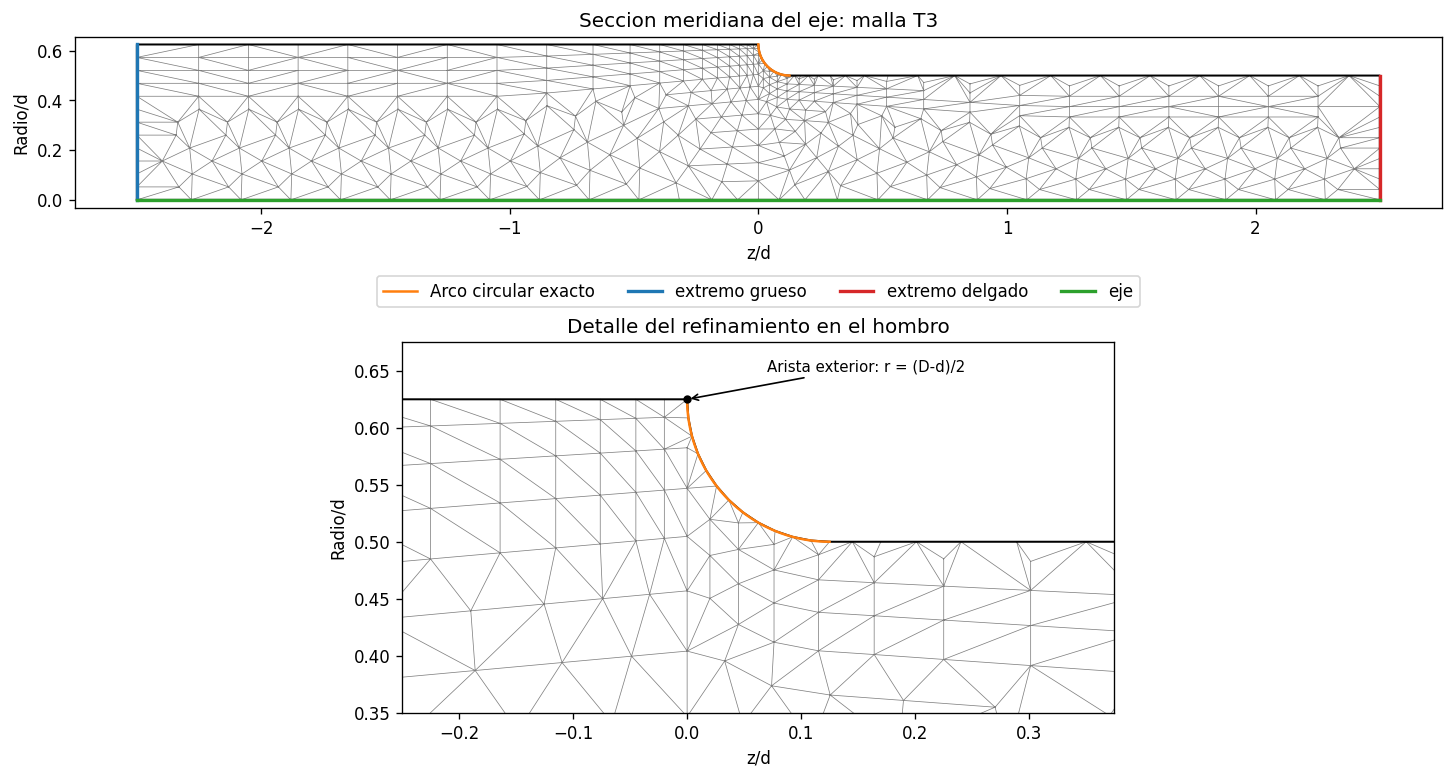

In [6]:
fig, ejes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)

exterior = coordenadas[bordes["nodos_exterior"]]
contorno = np.vstack(([0, -L_grueso], exterior,
                      [0, L_delgado], [0, -L_grueso]))
angulos = np.linspace(0, np.pi/2, 200)
z_arco = r_transicion*(1-np.cos(angulos))
radio_arco = d/2+r_transicion*(1-np.sin(angulos))

for ax in ejes:
    ax.triplot(coordenadas[:, 1]/d, coordenadas[:, 0]/d,
               conectividad, color="0.5", linewidth=0.45)
    ax.plot(contorno[:, 1]/d, contorno[:, 0]/d, color="black", linewidth=1.2)
    ax.plot(z_arco/d, radio_arco/d, color="tab:orange", linewidth=1.5,
            label="Arco circular exacto")
    ax.set_aspect("equal")
    ax.set_xlabel("z/d")
    ax.set_ylabel("Radio/d")

for nombre, color in [("extremo_grueso", "tab:blue"),
                      ("extremo_delgado", "tab:red"), ("eje", "tab:green")]:
    nodos = bordes["nodos_"+nombre]
    ejes[0].plot(coordenadas[nodos, 1]/d, coordenadas[nodos, 0]/d,
                 color=color, linewidth=2, label=nombre.replace("_", " "))

ejes[0].set_title("Seccion meridiana del eje: malla T3")
ejes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.35), ncol=4)
ejes[1].set_xlim(-0.25, r_transicion/d+0.25)
ejes[1].set_ylim(d/2/d-0.15, D/2/d+0.05)
ejes[1].plot(0, D/(2*d), "ko", markersize=4)
ejes[1].annotate("Arista exterior: r = (D-d)/2", xy=(0, D/(2*d)),
                 xytext=(0.07, D/(2*d)+0.025), fontsize=9,
                 arrowprops={"arrowstyle": "->"})
ejes[1].set_title("Detalle del refinamiento en el hombro")
plt.show()
